In [45]:
import numpy as np
from optiland import optic

In [46]:
from optiland.fileio import load_optiland_file, save_optiland_file
from optiland.fileio import load_zemax_file
from optiland.prescription import Prescription
from optiland.analysis import RayFan, RmsSpotSizeVsField, SpotDiagram
from optiland.diagnostics import check_system
from optiland.optic import Optic
from optiland.solves import QuickFocusSolve
from optiland.optimization import OptimizationProblem, OptimizerGeneric

In [68]:
wavelength = 1.55
num_field = 10
separation = 0.2
fields = np.arange(0, num_field*separation, separation)
aperture_diam = 40
interferometer = 300


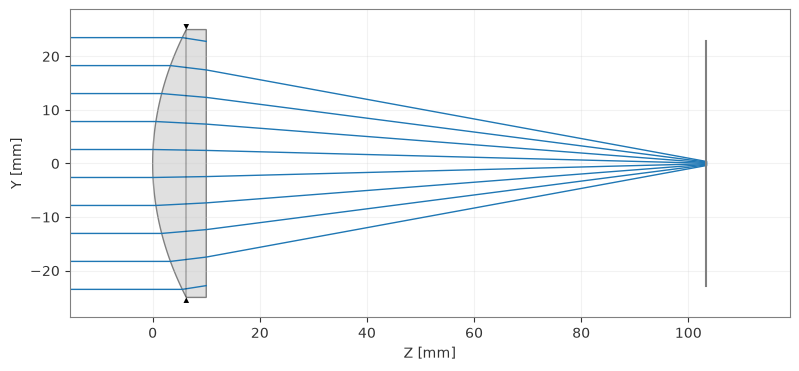

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [69]:
AL50100_C = load_zemax_file("C:/Users/saten/Documents/Umberto/OpticalEngineering/PilotReceiver/AL50100-C-Zemax-ZMX.zmx")
AL50100_C.wavelengths.remove(index = 0)
AL50100_C.wavelengths.add(value = wavelength)
AL50100_C.draw(num_rays=10)

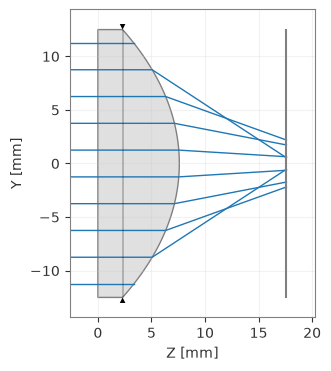

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [70]:
AL2520_C = load_zemax_file("C:/Users/saten/Documents/Umberto/OpticalEngineering/PilotReceiver/AL2520-C-Zemax-ZMX.zmx")
AL2520_C.wavelengths.remove(index = 0)
AL2520_C.wavelengths.add(value = wavelength)
AL2520_C.draw(num_rays=10)
#AL2520_C.surfaces[-1].thickness = 10

C:\Users\saten\AppData\Local\Temp\ipykernel_27060\3074732872.py:5: DeprecationWarning: Optic.set_thickness is deprecated and will be removed in v0.7.0; use optic.updater.set_thickness() instead.
  BeamReducer.set_thickness(interferometer, surface_number=4)


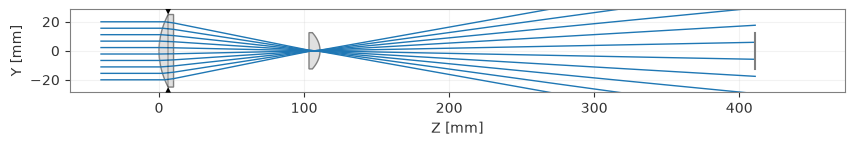

Surface 0: inf
Surface 1: 10.0
Surface 2: 93.3859313897
Surface 3: 7.6
Surface 4: 300
Surface 5: 0.0


In [71]:
BeamReducer = AL50100_C + AL2520_C
BeamReducer.wavelengths.remove(index = 0)
BeamReducer.wavelengths.add(value = wavelength)
BeamReducer.set_aperture(aperture_type="EPD", value=aperture_diam)
BeamReducer.set_thickness(interferometer, surface_number=4)   
BeamReducer.draw(num_rays=10)
for i in range(len(BeamReducer.surfaces)):
    print(f"Surface {i}: {BeamReducer.surfaces[i].thickness}")


In [72]:
problem = OptimizationProblem()

problem.add_variable(BeamReducer, "thickness", surface_number=2)

problem.add_operand(
    "AOI",
    target=0.0,
    weight=1.0,
    input_data={
        "optic": BeamReducer,
        "Hx": 0.0,
        "Hy": 0.0,
        "Px": 0.0,
        "Py": 1,
        "num_rings": 6,
        "wavelength": wavelength,
        "surface_number": -1,  # the image surface
    },
)

print(f"Merit function before: {float(problem.sum_squared()):.6f}")
OptimizerGeneric(problem).optimize(maxiter=10000)
print(f"Merit function after: {float(problem.sum_squared()):.6f}")

c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\optimization\optimizer\scipy\base.py:110: OptimizeWarning: Unknown solver options: disp
  result = optimize.minimize(


Merit function before: 102.205080
Merit function after: 0.000000


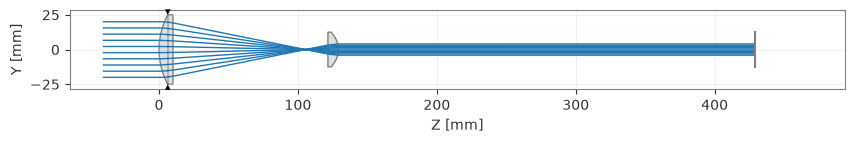

Surface 0: inf
Surface 1: 10.0
Surface 2: 111.59049130486243
Surface 3: 7.6
Surface 4: 300
Surface 5: 0.0
429.19049130486246


In [73]:
BeamReducer.draw(num_rays=10)
for i in range(len(BeamReducer.surfaces)):
    print(f"Surface {i}: {BeamReducer.surfaces[i].thickness}")
print(np.sum([s.thickness for s in BeamReducer.surfaces if np.isfinite(s.thickness)]))


Merit function before: 0.003754


c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\optimization\optimizer\scipy\base.py:110: OptimizeWarning: Unknown solver options: disp
  result = optimize.minimize(


Merit function after: 0.000002
Surface 0: inf
Surface 1: 10.0
Surface 2: 111.59049130486243
Surface 3: 7.6
Surface 4: 300
Surface 5: 4.25
Surface 6: 7.819029746161729
Surface 7: 0.0
441.2595210510242


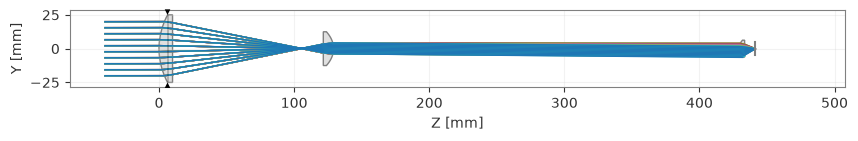

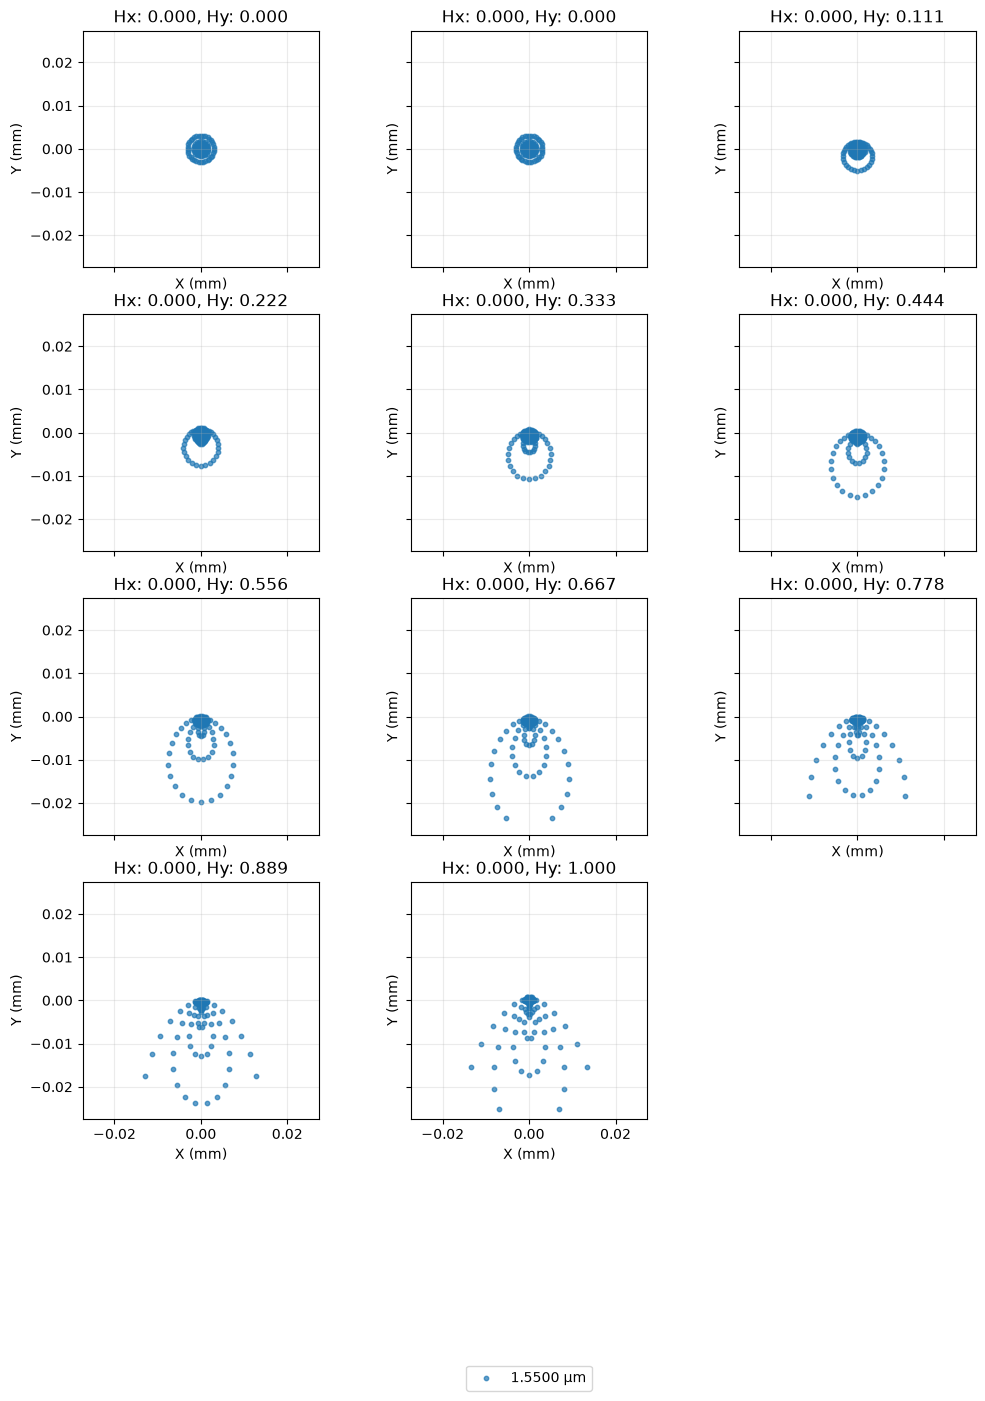

Field 0.0: RMS spot radius = [np.float64(0.0019388718959035618)] um, Maximum ray radius = [np.float64(0.003092491955654515)] um, Centroid = (np.float64(8.698204011827014e-17), np.float64(-1.0053200616684489e-17)) um
Field 0.2: RMS spot radius = [np.float64(0.0019388718959035618)] um, Maximum ray radius = [np.float64(0.003092491955654515)] um, Centroid = (np.float64(8.698204011827014e-17), np.float64(-1.0053200616684489e-17)) um
Field 0.4: RMS spot radius = [np.float64(0.002141891605870458)] um, Maximum ray radius = [np.float64(0.005072907223139023)] um, Centroid = (np.float64(-1.0577715431468027e-16), np.float64(-0.010541095682349254)) um
Field 0.6000000000000001: RMS spot radius = [np.float64(0.0027066519650138193)] um, Maximum ray radius = [np.float64(0.007610664630776587)] um, Centroid = (np.float64(-1.997527252967309e-16), np.float64(-0.021119961280254604)) um
Field 0.8: RMS spot radius = [np.float64(0.0035739160124692105)] um, Maximum ray radius = [np.float64(0.010812616205689962)

In [75]:
FocusingOptics = load_zemax_file("C:/Users/saten/Documents/Umberto/OpticalEngineering/PilotReceiver/AL1210-C-Zemax-ZMX.zmx")
FocusingOptics.wavelengths.remove(index = 0)
FocusingOptics.wavelengths.add(value = wavelength)
ReceiverBranch = BeamReducer + FocusingOptics

ReceiverBranch.fields.set_type(field_type="angle")
for i in range(len(fields)):
    ReceiverBranch.fields.add(180/np.pi * fields[i] / 1000)

problem = OptimizationProblem()

problem.add_variable(ReceiverBranch, "thickness", surface_number=6)

problem.add_operand(
    "rms_spot_size",
    target=0.0,
    weight=1.0,
    input_data={
        "optic": ReceiverBranch,
        "Hx": 0.0,
        "Hy": 0.0,
        "num_rings": 6,
        "wavelength": wavelength,
        "surface_number": -1,  # the image surface
    },
)

print(f"Merit function before: {float(problem.sum_squared()):.6f}")
OptimizerGeneric(problem).optimize(maxiter=200)
print(f"Merit function after: {float(problem.sum_squared()):.6f}")

for i in range(len(ReceiverBranch.surfaces)):
    print(f"Surface {i}: {ReceiverBranch.surfaces[i].thickness}")
print(np.sum([s.thickness for s in ReceiverBranch.surfaces if np.isfinite(s.thickness)]))

ReceiverBranch.draw(num_rays=10)

spot = SpotDiagram(ReceiverBranch, num_rings = 6, fields = "all")
spot.view()

for i in range(len(fields)):
    print(f"Field {fields[i]}: RMS spot radius = {spot.rms_spot_radius()[i]} um, Maximum ray radius = {spot.geometric_spot_radius()[i]} um, Centroid = {spot.centroid()[i]} um")

print("Vignetting on AL1210 happens at around 1.2 - 1.4 mrad")

In [39]:
p = Prescription(ReceiverBranch)
p.view()

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Optical Prescription — AL50100-C Ø50 mm, f=100 mm, NA=0.240, N-BK7 Aspheric Lens, ARC: 1050-1620 nm             │
╰──────────────────────────────────────── Generated: 2026-11-11 11:44 UTC ────────────────────────────────────────╯

───────────────────────────────────────────────── System Overview ─────────────────────────────────────────────────

 Name              AL50100-C Ø50 mm, f=100 mm, NA=0.240, N-BK7 Aspheric Lens, ARC: 1050-1620 nm  
  Surfaces          6                                                                             
  Stop Surface      1.0000                                                                        
  Aperture Type     EPDAperture                                                                   
  Aperture Value    40.0000                                                                       
  Object Distance   ∞                                                                             
  Image Distance    7.8190                                                                       

 Wavelengths

 #   Wavelength (µm)   Primary  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1   1.5500            ✓

 Fields

... (5 outputs left out)

──────────────────────────────────────────── Surface Data — Materials ─────────────────────────────────────────────

 S#   Material   nd       Vd        Semi-Diameter (mm)   Coating  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0    Air        1.0000   —         —                    —        
  1    N-BK7      1.5168   64.1673   —                    —        
  2    Air        1.0000   —         —                    —        
  3    S-LAH64    1.7880   47.3685   —                    —        
  4    Air        1.0000   —         —                    —        
  5    S-LAH64    1.7880   47.3685   —                    —        
  6    Air        1.0000   —         —                    —        
  7    Air        1.0000   —         —                    —       

───────────────────────────────────────── Seidel Aberration Coefficients ──────────────────────────────────────────

 S#      SI (Sph)    SII (Coma)   SIII (Astig)   SIV (Petz)   SV (Dist)   CL (LCA)   CT (TCA)  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1       0.078517    -0.001157    -0.000005      -0.000008    -0.000000   N/A        N/A       
  2       -0.078104   0.000678     -0.000006      0.000000     0.000000    N/A        N/A       
  3       -0.016095   0.000140     -0.000001      -0.000000    0.000000    N/A        N/A       
  4       0.053662    -0.002233    0.000069       -0.000032    0.000003    N/A        N/A       
  5       0.270799    0.157615     0.091684       -0.000064    0.053260    N/A        N/A       
  6       -0.119487   -0.067858    -0.038538      0.000000     -0.021886   N/A        N/A       
  Total   0.189292    0.087184     0.053202       -0.000104    0.031377    N/A        N/A

In [40]:
from optiland.coordinate_system import CoordinateSystem

class RigidLensPerturbation:
    """Move a group of surfaces as one rigid body.

    mode: 'tilt_x' / 'tilt_y' (radians, about `pivot`) or 'dx' / 'dy' / 'dz' (lens units).
    pivot: global (x, y, z) point to rotate about; default = vertex of the first surface.
    """

    def __init__(self, optic, surfaces, mode, sampler, pivot=None):
        self.optic, self.surfaces, self.mode, self.sampler = optic, list(surfaces), mode, sampler
        S = optic.surface_group.surfaces
        self._cs = [S[i].geometry.cs for i in self.surfaces]
        for cs in self._cs:
            if cs.reference_cs is not None:
                raise NotImplementedError("Surface uses a reference_cs; pivot math assumes global coordinates.")
        self._nominal = [tuple(float(v) for v in (cs.x, cs.y, cs.z, cs.rx, cs.ry)) for cs in self._cs]
        self.pivot = np.asarray(pivot if pivot is not None else self._nominal[0][:3], dtype=float)
        self.variable = f"rigid {mode}, surfaces {self.surfaces}"   # used as the label in results
        self.value = None

    def apply(self):
        self.value = float(self.sampler.sample())
        self._set(self.value)

    def reset(self):
        self._set(0.0)

    def _set(self, v):
        tx = v if self.mode == "tilt_x" else 0.0
        ty = v if self.mode == "tilt_y" else 0.0
        shift = np.zeros(3)
        if self.mode in ("dx", "dy", "dz"):
            shift["xyz".index(self.mode[1])] = v
        # Use Optiland's own rotation matrix so the sign convention matches its ray tracing
        R = np.asarray(CoordinateSystem(rx=tx, ry=ty).get_rotation_matrix(), dtype=float)
        for cs, (x, y, z, rx, ry) in zip(self._cs, self._nominal):
            cs.x, cs.y, cs.z = self.pivot + R @ (np.array([x, y, z]) - self.pivot) + shift
            cs.rx, cs.ry = rx + tx, ry + ty


In [41]:
from optiland.tolerancing import RangeSampler, SensitivityAnalysis, Tolerancing

tolerancing_thickness = Tolerancing(ReceiverBranch)
tolerancing_decenter = Tolerancing(ReceiverBranch)
tolerancing_tilt = Tolerancing(ReceiverBranch)

# thickness
sampler = RangeSampler(start=ReceiverBranch.surfaces[2].thickness-0.1, end=ReceiverBranch.surfaces[2].thickness+0.1, steps=200)
tolerancing_thickness.add_perturbation("thickness", sampler, surface_number=2)
sampler = RangeSampler(start=interferometer-10, end=interferometer+10, steps=200)
tolerancing_thickness.add_perturbation("thickness", sampler, surface_number=4)
sampler = RangeSampler(start=ReceiverBranch.surfaces[6].thickness-0.05, end=ReceiverBranch.surfaces[6].thickness+0.05, steps=200)
tolerancing_thickness.add_perturbation("thickness", sampler, surface_number=6)

# decenter
sampler = RangeSampler(start=-0.5, end=0.5, steps=200)
rigid = RigidLensPerturbation(ReceiverBranch, [1, 2, 3], "BR_dy", sampler)
tolerancing_decenter.perturbations.append(rigid)
sampler = RangeSampler(start=-0.5, end=0.5, steps=200)
rigid = RigidLensPerturbation(ReceiverBranch, [5, 6], "fo_dy", sampler)
tolerancing_decenter.perturbations.append(rigid)

# tilt
sampler = RangeSampler(start=-0.051, end=0.051, steps=200)
pivot = 50
rigid = RigidLensPerturbation(ReceiverBranch, [1, 2, 3], "BR_tilt", sampler, pivot)
tolerancing_tilt.perturbations.append(rigid)
sampler = RangeSampler(start=-0.051, end=0.051, steps=200)
pivot = 433.45
rigid = RigidLensPerturbation(ReceiverBranch, [5, 6], "fo_tilt", sampler, pivot)
tolerancing_tilt.perturbations.append(rigid)

toleracings = [tolerancing_thickness, tolerancing_decenter, tolerancing_tilt]
pert_types = ["thickness", "decenter", "tilt"]

input_data_f2 = {"optic": ReceiverBranch}
input_data_rms = {
    "optic": ReceiverBranch,
    "surface_number": -1,
    "Hx": 0,
    "Hy": 0.0,
    "wavelength": wavelength,
    "num_rays": 10,
}  # surface_number=-1 means the last surface
input_data_centroid = {
    "optic": ReceiverBranch,
    "surface_number": -1,
    "Hx": 0.0,
    "Hy": 0.0,
    "Px": 0,
    "Py": 0,
    "wavelength": wavelength,
}  # surface_number=-1 means the last surface

inputs = [input_data_f2, input_data_rms, input_data_centroid]
operand_list = ["f2", "rms_spot_size", "real_y_intercept"]

for i in range(len(toleracings)):
    for j in range(len(operand_list)):
        toleracings[i].add_operand(operand_list[j], inputs[j])

sensitivity_analysis = []
for i in range(len(toleracings)):
    sensitivity_analysis.append(SensitivityAnalysis(toleracings[i])) 
    sensitivity_analysis[i].run()

C:\Users\saten\AppData\Local\Temp\ipykernel_27060\3306002784.py:12: DeprecationWarning: Optic.surface_group is deprecated; use Optic.surfaces instead.
  S = optic.surface_group.surfaces


(<Figure size 990x750 with 9 Axes>,
 [<Axes: ylabel='0: f2'>,
  <Axes: >,
  <Axes: >,
  <Axes: ylabel='1: rms spot size'>,
  <Axes: >,
  <Axes: >,
  <Axes: xlabel='Thickness, Surface 2', ylabel='2: real y intercept'>,
  <Axes: xlabel='Thickness, Surface 4'>,
  <Axes: xlabel='Thickness, Surface 6'>])

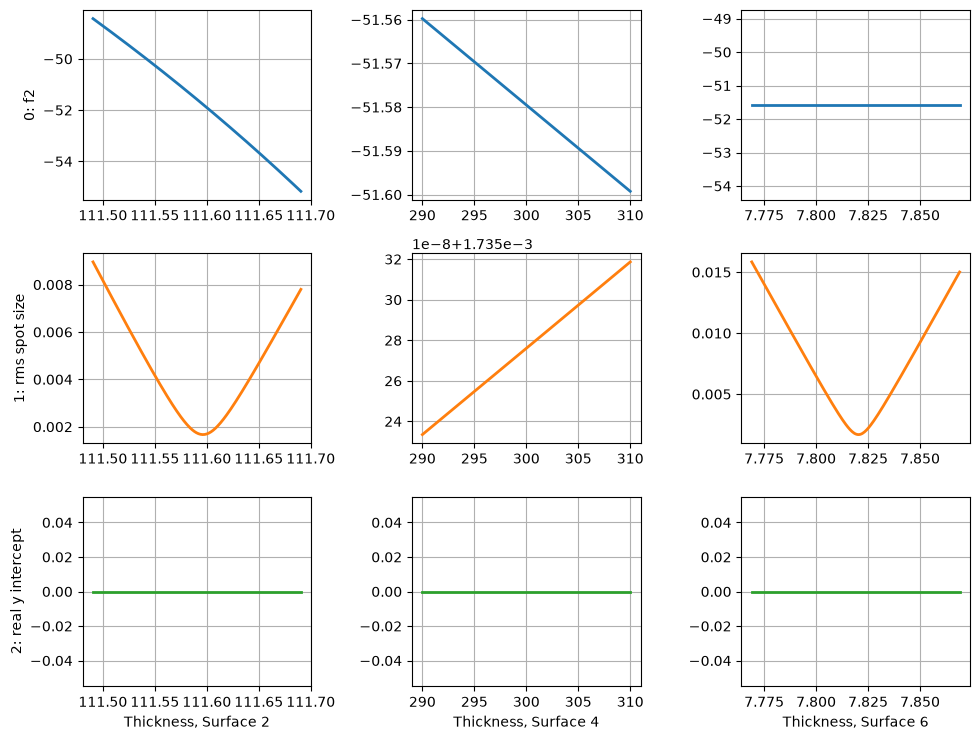

In [42]:
sensitivity_analysis[0].view(sharex="none", sharey="none")

(<Figure size 660x750 with 6 Axes>,
 [<Axes: ylabel='0: f2'>,
  <Axes: >,
  <Axes: ylabel='1: rms spot size'>,
  <Axes: >,
  <Axes: xlabel='rigid BR_dy, surfaces [1, 2, 3]', ylabel='2: real y intercept'>,
  <Axes: xlabel='rigid fo_dy, surfaces [5, 6]'>])

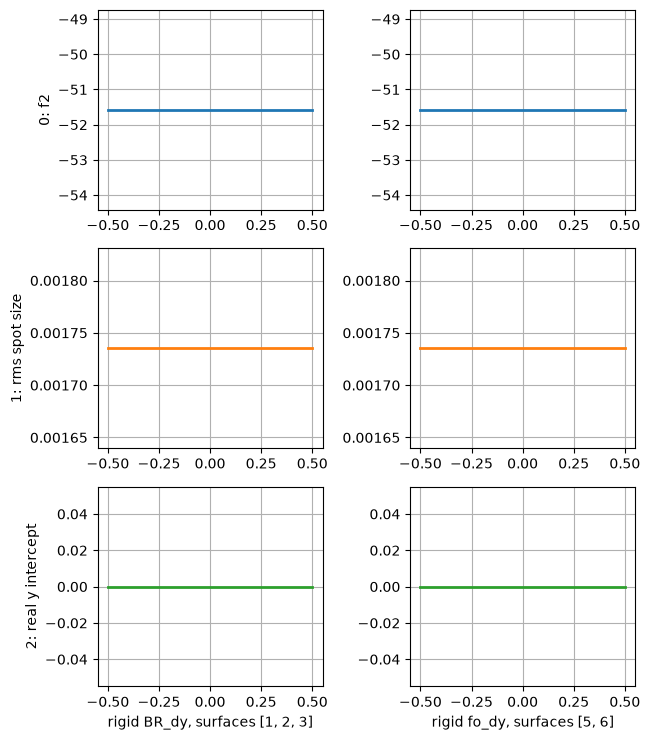

In [43]:
sensitivity_analysis[1].view(sharex="none", sharey="none")

(<Figure size 660x750 with 6 Axes>,
 [<Axes: ylabel='0: f2'>,
  <Axes: >,
  <Axes: ylabel='1: rms spot size'>,
  <Axes: >,
  <Axes: xlabel='rigid BR_tilt, surfaces [1, 2, 3]', ylabel='2: real y intercept'>,
  <Axes: xlabel='rigid fo_tilt, surfaces [5, 6]'>])

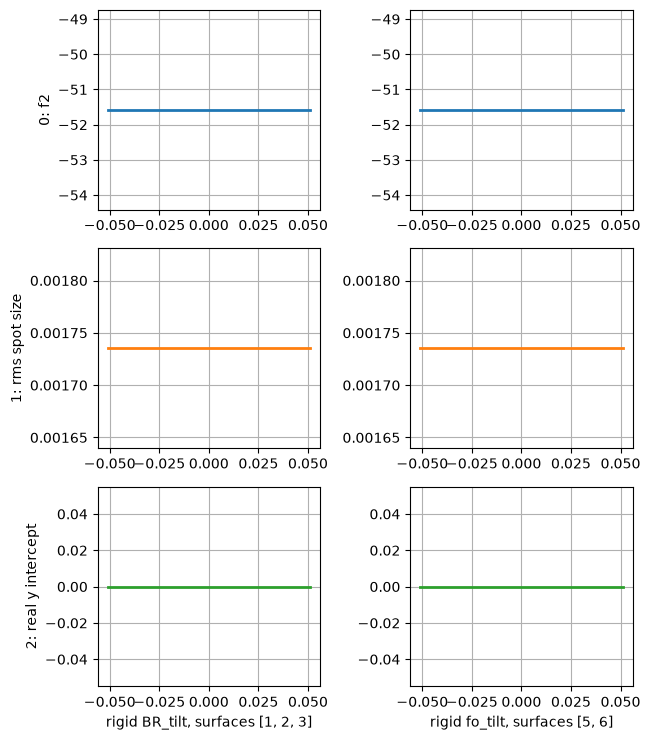

In [44]:
sensitivity_analysis[2].view(sharex="none", sharey="none")